In [4]:
import pandas as pd

url = "https://raw.githubusercontent.com/justmarkham/DAT8/master/data/chipotle.tsv"
df = pd.read_csv(url, sep="\t")
df.head()


,order_id,quantity,item_name,choice_description,item_price
0,1,1,Chips and Fresh Tomato Salsa,NaN,$2.39
1,1,1,Izze,[Clementine],$3.39
2,1,1,Nantucket Nectar,[Apple],$3.39
3,1,1,Chips and Tomatillo-Green Chili Salsa,NaN,$2.39
4,2,2,Chicken Bowl,"[Tomatillo-Red Chili Salsa (Hot), [Black Beans...",$16.98


In [5]:
df.shape

(4622, 5)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4622 entries, 0 to 4621
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   order_id            4622 non-null   int64 
 1   quantity            4622 non-null   int64 
 2   item_name           4622 non-null   object
 3   choice_description  3376 non-null   object
 4   item_price          4622 non-null   object
dtypes: int64(2), object(3)
memory usage: 180.7+ KB


In [7]:
df["item_name"].value_counts()

,count
item_name,
Chicken Bowl,726
Chicken Burrito,553
Chips and Guacamole,479
Steak Burrito,368
Canned Soft Drink,301
Chips,211
Steak Bowl,211
Bottled Water,162
Chicken Soft Tacos,115


In [8]:
df[["item_name", "choice_description"]].head(10)

,item_name,choice_description
0,Chips and Fresh Tomato Salsa,NaN
1,Izze,[Clementine]
2,Nantucket Nectar,[Apple]
3,Chips and Tomatillo-Green Chili Salsa,NaN
4,Chicken Bowl,"[Tomatillo-Red Chili Salsa (Hot), [Black Beans..."
5,Chicken Bowl,"[Fresh Tomato Salsa (Mild), [Rice, Cheese, Sou..."
6,Side of Chips,NaN
7,Steak Burrito,"[Tomatillo Red Chili Salsa, [Fajita Vegetables..."
8,Steak Soft Tacos,"[Tomatillo Green Chili Salsa, [Pinto Beans, Ch..."
9,Steak Burrito,"[Fresh Tomato Salsa, [Rice, Black Beans, Pinto..."


In [9]:
# 1. Keep only entrees (burritos, bowls, tacos, salads)
entree_pattern = "Burrito|Bowl|Tacos|Salad"
entrees = df[df["item_name"].str.contains(entree_pattern)].copy()

# 2. Extract the protein from the item name
def get_protein(name):
    for p in ["Chicken", "Steak", "Barbacoa", "Carnitas", "Veggie"]:
        if p in name:
            return p
    return "None"

entrees["protein"] = entrees["item_name"].apply(get_protein)

# 3. Did this entree include guac? (look in the choices text)
entrees["has_guac"] = entrees["choice_description"].str.contains(
    "Guacamole", case=False, na=False
)

# Check the result
print(entrees.shape)
entrees[["item_name", "protein", "has_guac"]].head(10)

(2870, 7)


,item_name,protein,has_guac
4,Chicken Bowl,Chicken,False
5,Chicken Bowl,Chicken,True
7,Steak Burrito,Steak,True
8,Steak Soft Tacos,Steak,False
9,Steak Burrito,Steak,False
11,Chicken Crispy Tacos,Chicken,False
12,Chicken Soft Tacos,Chicken,False
13,Chicken Bowl,Chicken,True
16,Chicken Burrito,Chicken,False
17,Chicken Burrito,Chicken,False


In [10]:
rates = (entrees[entrees["protein"] != "None"]
         .groupby("protein")["has_guac"]
         .agg(guac_rate="mean", orders="count")
         .sort_values("guac_rate", ascending=False))
rates

,guac_rate,orders
protein,,
Veggie,0.443396,212
Steak,0.364672,702
Chicken,0.356410,1560
Barbacoa,0.334975,203
Carnitas,0.331492,181


In [12]:
from scipy.stats import chi2_contingency

meats = entrees[entrees["protein"].isin(["Steak", "Chicken", "Barbacoa", "Carnitas"])]

# Steak vs Barbacoa
two = meats[meats["protein"].isin(["Steak", "Barbacoa"])]
chi2, p, dof, exp = chi2_contingency(pd.crosstab(two["protein"], two["has_guac"]))
print("Steak vs Barbacoa p-value:", round(p, 3))

# Any difference among the four meats?
chi2, p_all, dof, exp = chi2_contingency(pd.crosstab(meats["protein"], meats["has_guac"]))
print("Four meats p-value:", round(p_all, 3))

Steak vs Barbacoa p-value: 0.488
Four meats p-value: 0.779


In [13]:
# 1. Clean the price column ("$11.75 " -> 11.75) and get price per single entree
entrees["price"] = (entrees["item_price"]
                    .str.replace("$", "", regex=False)
                    .str.strip()
                    .astype(float))
entrees["unit_price"] = entrees["price"] / entrees["quantity"]

# 2. Median price by protein, with and without guac
(entrees[entrees["protein"] != "None"]
 .groupby(["protein", "has_guac"])["unit_price"]
 .median()
 .unstack())

has_guac,False,True
protein,,
Barbacoa,9.25,11.75
Carnitas,9.25,11.75
Chicken,8.75,11.25
Steak,9.25,11.75
Veggie,8.49,11.25


In [14]:
import numpy as np

s = two[two["protein"] == "Steak"]["has_guac"]
b = two[two["protein"] == "Barbacoa"]["has_guac"]

diff = s.mean() - b.mean()
se = np.sqrt(s.mean()*(1-s.mean())/len(s) + b.mean()*(1-b.mean())/len(b))

print("Difference:", round(diff*100, 1), "percentage points")
print("95% CI:", round((diff-1.96*se)*100, 1), "to", round((diff+1.96*se)*100, 1))

Difference: 3.0 percentage points
95% CI: -4.4 to 10.4


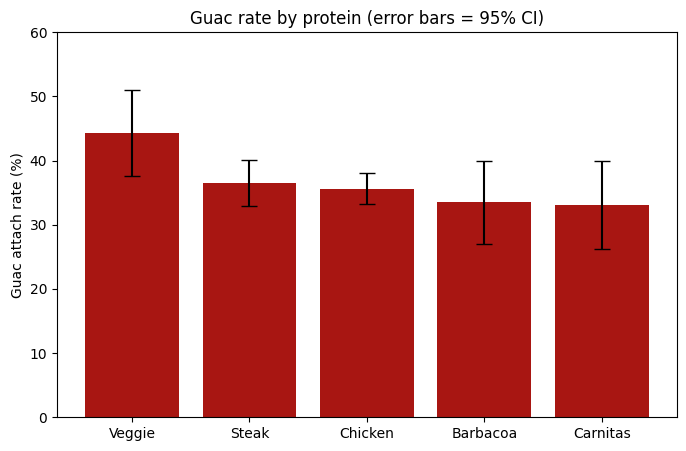

In [15]:
import matplotlib.pyplot as plt
import numpy as np

sub = entrees[entrees["protein"] != "None"]
g = sub.groupby("protein")["has_guac"].agg(rate="mean", n="count")
g["se"] = np.sqrt(g["rate"] * (1 - g["rate"]) / g["n"])
g["err"] = 1.96 * g["se"]
g = g.sort_values("rate", ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(g.index, g["rate"] * 100, yerr=g["err"] * 100, capsize=6, color="#A81612")
plt.ylabel("Guac attach rate (%)")
plt.title("Guac rate by protein (error bars = 95% CI)")
plt.ylim(0, 60)
plt.show()

In [16]:
from scipy.stats import chi2_contingency

sub2 = sub.copy()
sub2["is_veggie"] = sub2["protein"] == "Veggie"
chi2, p, dof, exp = chi2_contingency(pd.crosstab(sub2["is_veggie"], sub2["has_guac"]))
print("Veggie vs meats p-value:", round(p, 4))


Veggie vs meats p-value: 0.0126


In [17]:
import numpy as np

v = sub[sub["protein"] == "Veggie"]["has_guac"]
m = sub[sub["protein"] != "Veggie"]["has_guac"]

diff = v.mean() - m.mean()
se = np.sqrt(v.mean()*(1-v.mean())/len(v) + m.mean()*(1-m.mean())/len(m))

print("Veggie rate:", round(v.mean()*100, 1), "% (n =", len(v), ")")
print("Meat rate:", round(m.mean()*100, 1), "% (n =", len(m), ")")
print("Difference:", round(diff*100, 1), "percentage points")
print("95% CI:", round((diff-1.96*se)*100, 1), "to", round((diff+1.96*se)*100, 1))

Veggie rate: 44.3 % (n = 212 )
Meat rate: 35.5 % (n = 2646 )
Difference: 8.8 percentage points
95% CI: 1.9 to 15.7


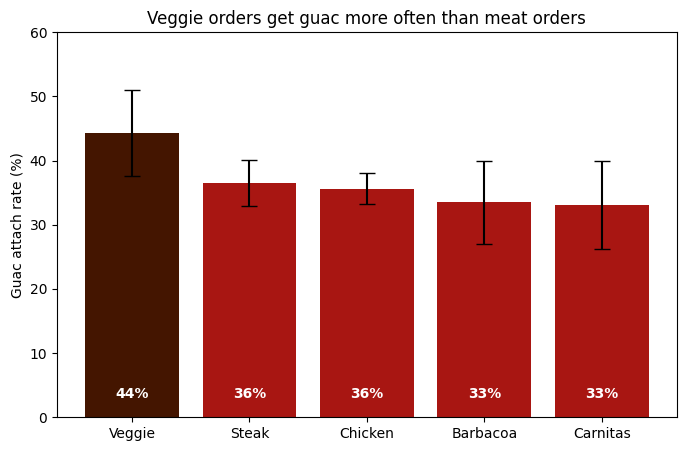

In [18]:
plt.figure(figsize=(8, 5))
colors = ["#441500" if p == "Veggie" else "#A81612" for p in g.index]
bars = plt.bar(g.index, g["rate"] * 100, yerr=g["err"] * 100, capsize=6, color=colors)
for bar, r in zip(bars, g["rate"] * 100):
    plt.text(bar.get_x() + bar.get_width()/2, 3, f"{r:.0f}%",
             ha="center", color="white", fontweight="bold")
plt.ylabel("Guac attach rate (%)")
plt.title("Veggie orders get guac more often than meat orders")
plt.ylim(0, 60)
plt.show()

In [19]:
upcharge = 2.50
meat_rate = m.mean()      # from the last step
veg_rate = v.mean()

# Revenue per entree from guac
print("Guac revenue per meat entree: $", round(meat_rate * upcharge, 2))
print("Guac revenue per veggie entree: $", round(veg_rate * upcharge, 2))

# What-if: meat customers ordered guac at the veggie rate
lift_pts = veg_rate - meat_rate
per_1000 = lift_pts * upcharge * 1000
print("Extra revenue per 1,000 meat entrees: $", round(per_1000))

# Range from the confidence interval (1.9 to 15.7 points)
for pts in [0.019, 0.157]:
    print(f"If gap is {pts*100:.1f} pts: $", round(pts * upcharge * 1000))

Guac revenue per meat entree: $ 0.89
Guac revenue per veggie entree: $ 1.11
Extra revenue per 1,000 meat entrees: $ 220
If gap is 1.9 pts: $ 48
If gap is 15.7 pts: $ 392


In [20]:
sub = entrees[entrees["protein"] != "None"].copy()
sub["guac_units"] = sub["has_guac"] * sub["quantity"]

w = sub.groupby("protein").agg(guac=("guac_units", "sum"), n=("quantity", "sum"))
w["rate_pct"] = (w["guac"] / w["n"] * 100).round(1)
w.sort_values("rate_pct", ascending=False)

,guac,n,rate_pct
protein,,,
Veggie,96,217,44.2
Steak,266,734,36.2
Chicken,581,1654,35.1
Carnitas,63,186,33.9
Barbacoa,68,204,33.3


In [21]:
veg = entrees[entrees["protein"] == "Veggie"].copy()
veg["type"] = veg["item_name"].str.extract(r"(Burrito|Bowl|Tacos|Salad)")
veg.groupby(["type", "has_guac"])["unit_price"].median().unstack()

has_guac,False,True
type,,
Bowl,8.75,11.25
Burrito,8.49,11.25
Salad,8.75,11.25
Tacos,8.49,11.25


In [22]:
# Flag the chips-and-guac side
df["is_chips_guac"] = df["item_name"] == "Chips and Guacamole"

# Per order: did any entree have guac? did the order include the side?
entree_guac = entrees.groupby("order_id")["has_guac"].any().rename("entree_guac")
chips_guac = df.groupby("order_id")["is_chips_guac"].any().rename("chips_guac")

# join="inner" keeps only orders that contain at least one entree
o = pd.concat([entree_guac, chips_guac], axis=1, join="inner")

print("Orders with an entree:", len(o))
print(pd.crosstab(o["entree_guac"], o["chips_guac"], margins=True))
print()
# Row percentages: among orders with / without entree guac, how many also got the side?
print((pd.crosstab(o["entree_guac"], o["chips_guac"], normalize="index") * 100).round(1))

Orders with an entree: 1832
chips_guac   False  True   All
entree_guac                   
False          748   294  1042
True           611   179   790
All           1359   473  1832

chips_guac   False  True 
entree_guac              
False         71.8   28.2
True          77.3   22.7


In [23]:
from scipy.stats import chi2_contingency
chi2, p, dof, exp = chi2_contingency(pd.crosstab(o["entree_guac"], o["chips_guac"]))
print("Entree guac vs chips-and-guac side, p-value:", round(p, 4))

o["any_guac"] = o["entree_guac"] | o["chips_guac"]
print("Orders with guac in any form:", round(o["any_guac"].mean() * 100, 1), "%")

Entree guac vs chips-and-guac side, p-value: 0.0084
Orders with guac in any form: 59.2 %


In [24]:
a = o[o["entree_guac"] == False]["chips_guac"]
b = o[o["entree_guac"] == True]["chips_guac"]

diff = a.mean() - b.mean()
se = np.sqrt(a.mean()*(1-a.mean())/len(a) + b.mean()*(1-b.mean())/len(b))
print("Gap:", round(diff*100, 1), "points")
print("95% CI:", round((diff-1.96*se)*100, 1), "to", round((diff+1.96*se)*100, 1))

# What does the side cost in this data?
side = df[df["is_chips_guac"]].copy()
side["price"] = side["item_price"].str.replace("$", "", regex=False).str.strip().astype(float)
side["unit_price"] = side["price"] / side["quantity"]
print("Median side price: $", side["unit_price"].median())

Gap: 5.6 points
95% CI: 1.6 to 9.6
Median side price: $ 4.45


In [25]:
n_ent = entrees.groupby("order_id")["quantity"].sum().rename("n_entrees")
o2 = o.join(n_ent)
o2["size"] = pd.cut(o2["n_entrees"], [0, 1, 2, 100], labels=["1", "2", "3+"])

# Guac behavior by order size
print(o2.groupby("size", observed=True).agg(
    orders=("entree_guac", "size"),
    entree_guac=("entree_guac", "mean"),
    side=("chips_guac", "mean"),
    any_guac=("any_guac", "mean")).round(3))

# Substitution check within single-entree orders only
single = o2[o2["n_entrees"] == 1]
print()
print(pd.crosstab(single["entree_guac"], single["chips_guac"], normalize="index").round(3) * 100)
chi2, p, dof, exp = chi2_contingency(pd.crosstab(single["entree_guac"], single["chips_guac"]))
print("Single-entree p-value:", round(p, 4))

      orders  entree_guac   side  any_guac
size                                      
1        991        0.363  0.318     0.597
2        668        0.493  0.159     0.557
3+       173        0.584  0.301     0.694

chips_guac   False  True 
entree_guac              
False         63.2   36.8
True          76.9   23.1
Single-entree p-value: 0.0


In [26]:
single = o2[o2["n_entrees"] == 1]
a = single[single["entree_guac"] == False]["chips_guac"]
b = single[single["entree_guac"] == True]["chips_guac"]

diff = a.mean() - b.mean()
se = np.sqrt(a.mean()*(1-a.mean())/len(a) + b.mean()*(1-b.mean())/len(b))
lo, hi = diff - 1.96*se, diff + 1.96*se

print("Single-entree gap:", round(diff*100, 1), "points")
print("95% CI:", round(lo*100, 1), "to", round(hi*100, 1))
print("Side revenue given up per 1,000 guac entrees: $", round(diff*4.45*1000),
      f"(range ${lo*4.45*1000:.0f} to ${hi*4.45*1000:.0f})")
print("Share of the $2.50 add-on:", round(diff*4.45/2.50*100), "%")

Single-entree gap: 13.7 points
95% CI: 8.0 to 19.5
Side revenue given up per 1,000 guac entrees: $ 610 (range $354 to $866)
Share of the $2.50 add-on: 24 %


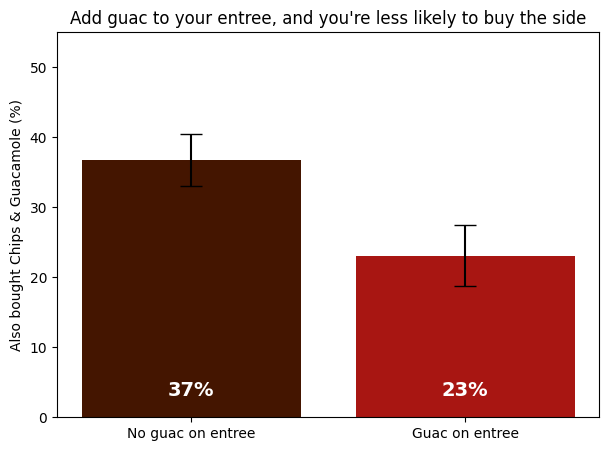

In [27]:
import matplotlib.pyplot as plt

grp = single.groupby("entree_guac")["chips_guac"].agg(rate="mean", n="count")
grp["err"] = 1.96 * np.sqrt(grp["rate"] * (1 - grp["rate"]) / grp["n"])
labels = ["No guac on entree", "Guac on entree"]

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, grp["rate"] * 100, yerr=grp["err"] * 100,
               capsize=8, color=["#441500", "#A81612"])
for bar, r in zip(bars, grp["rate"] * 100):
    plt.text(bar.get_x() + bar.get_width()/2, 3, f"{r:.0f}%",
             ha="center", color="white", fontweight="bold", fontsize=14)
plt.ylabel("Also bought Chips & Guacamole (%)")
plt.title("Add guac to your entree, and you're less likely to buy the side")
plt.ylim(0, 55)
plt.savefig("guac_substitution.png", dpi=200, bbox_inches="tight")
plt.show()